# Khám phá và tiền xử lý dữ liệu RT_IOT2022

**Đồ án cuối kỳ môn Máy học — phần 3.2: EDA và tiền xử lý.**  
Dữ liệu gốc: `RT_IOT2022.csv` (không thay đổi tập gốc). Mục tiêu: phân loại **12 nhãn `Attack_type`** của lưu lượng mạng IoT.

**Quy tắc chống rò rỉ dữ liệu:** xóa bản sao trùng hoàn toàn và các đặc trưng mâu thuẫn trước khi chia, chia train/test phân tầng cố định; **chỉ `fit` bộ mã hóa và chuẩn hóa trên train**, sau đó `transform` test. Tránh dùng test để chọn mô hình hoặc siêu tham số.

**Dữ liệu xuất:** `rt_iot_eda_outputs/train.csv.gz`, `test.csv.gz`, bộ xử lý riêng cho Random Forest và MLP (`.joblib`), metadata, hình EDA. File `.csv.gz` đọc trực tiếp bằng `pd.read_csv(path)`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

RANDOM_STATE = 42
DATA_PATH = Path("RT_IOT2022.csv")
OUTPUT_DIR = Path("rt_iot_eda_outputs")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.exists(), f"Không tìm thấy {DATA_PATH}. Hãy đặt CSV cùng thư mục với notebook."
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 15)
print('Đã sẵn sàng. File dữ liệu:', DATA_PATH.resolve())

Đã sẵn sàng. File dữ liệu: /mnt/data/RT_IOT2022.csv


## 1. Đọc dữ liệu và khảo sát cấu trúc

Quan sát kích thước, kiểu dữ liệu, bản ghi mẫu và thống kê mô tả để hiểu các thuộc tính trước khi chỉnh sửa.

In [2]:
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Kích thước: {df.shape[0]:,} dòng × {df.shape[1]} cột")
print("\nKiểu dữ liệu:")
display(df.dtypes.value_counts().rename("Số cột").to_frame())
display(df.head())
print("\nThống kê mô tả (một số cột):")
display(df.select_dtypes(include="number").describe().T.head(15).round(3))

Kích thước: 123,117 dòng × 85 cột

Kiểu dữ liệu:


,Số cột
float64,56
int64,26
object,3


,Unnamed: 0,id.orig_p,id.resp_p,proto,service,flow_duration,fwd_pkts_tot,...,idle.tot,idle.avg,idle.std,fwd_init_window_size,bwd_init_window_size,fwd_last_window_size,Attack_type
0,0,38667,1883,tcp,mqtt,32.011598,9,...,2.972918e+07,2.972918e+07,0.0,64240,26847,502,MQTT_Publish
1,1,51143,1883,tcp,mqtt,31.883584,9,...,2.985528e+07,2.985528e+07,0.0,64240,26847,502,MQTT_Publish
2,2,44761,1883,tcp,mqtt,32.124053,9,...,2.984215e+07,2.984215e+07,0.0,64240,26847,502,MQTT_Publish
3,3,60893,1883,tcp,mqtt,31.961063,9,...,2.991377e+07,2.991377e+07,0.0,64240,26847,502,MQTT_Publish
4,4,51087,1883,tcp,mqtt,31.902362,9,...,2.981470e+07,2.981470e+07,0.0,64240,26847,502,MQTT_Publish



Thống kê mô tả (một số cột):


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,123117.0,37035.089,30459.106,0.0,6059.000,33100.000,63879.0,94658.000
id.orig_p,123117.0,34639.259,19070.620,0.0,17702.000,37221.000,50971.0,65535.000
id.resp_p,123117.0,1014.305,5256.372,0.0,21.000,21.000,21.0,65389.000
flow_duration,123117.0,3.810,130.005,0.0,0.000,0.000,0.0,21728.336
fwd_pkts_tot,123117.0,2.269,22.337,0.0,1.000,1.000,1.0,4345.000
bwd_pkts_tot,123117.0,1.910,33.018,0.0,1.000,1.000,1.0,10112.000
fwd_data_pkts_tot,123117.0,1.471,19.635,0.0,1.000,1.000,1.0,4345.000
bwd_data_pkts_tot,123117.0,0.820,32.294,0.0,0.000,0.000,0.0,10105.000
fwd_pkts_per_sec,123117.0,351806.328,370764.493,0.0,74.544,246723.765,524288.0,1048576.000
bwd_pkts_per_sec,123117.0,351761.960,370801.485,0.0,72.889,246723.765,524288.0,1048576.000


## 2. Đánh giá chất lượng dữ liệu

Kiểm tra missing, ±∞, chỉ mục không có ý nghĩa, cột hằng số, dòng trùng sau khi bỏ chỉ mục và **xung đột nhãn** (các đặc trưng giống hệt nhưng `Attack_type` khác nhau). Không suy đoán lại nhãn từ dữ liệu.

In [3]:
missing = df.isna().sum().sort_values(ascending=False)
numeric = df.select_dtypes(include="number")
inf_total = int(np.isinf(numeric.to_numpy()).sum())
index_cols = [c for c in df.columns if c == "Unnamed: 0"]
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
without_index = df.drop(columns=index_cols)
exact_dups = int(without_index.duplicated().sum())
unique_rows = without_index.drop_duplicates().copy()
feature_cols_temp = [c for c in unique_rows.columns if c != "Attack_type"]
conflicting_mask = unique_rows.duplicated(subset=feature_cols_temp, keep=False)
conflict_rows = unique_rows.loc[conflicting_mask].copy()
conflict_groups = int(conflict_rows.groupby(feature_cols_temp, dropna=False).ngroups) if len(conflict_rows) else 0
quality = pd.DataFrame({
    "Hạng mục": ["Giá trị thiếu", "Giá trị ±∞", "Cột chỉ mục", "Cột hằng số", "Bản sao trùng (bỏ chỉ mục)", "Hàng có đặc trưng trùng nhưng nhãn mâu thuẫn", "Nhóm đặc trưng có nhãn mâu thuẫn"],
    "Kết quả": [int(missing.sum()), inf_total, index_cols, constant_cols, exact_dups, len(conflict_rows), conflict_groups]
})
display(quality)
print("Top 10 cột thiếu:")
display(missing.head(10).to_frame("Số missing"))
print("Các lớp của hàng có nhãn mâu thuẫn:")
display(conflict_rows["Attack_type"].value_counts().to_frame("Số hàng"))

,Hạng mục,Kết quả
0,Giá trị thiếu,0
1,Giá trị ±∞,0
2,Cột chỉ mục,[Unnamed: 0]
3,Cột hằng số,[bwd_URG_flag_count]
4,Bản sao trùng (bỏ chỉ mục),5195
5,Hàng có đặc trưng trùng nhưng nhãn mâu thuẫn,13
6,Nhóm đặc trưng có nhãn mâu thuẫn,6


Top 10 cột thiếu:


,Số missing
Unnamed: 0,0
id.orig_p,0
id.resp_p,0
proto,0
service,0
flow_duration,0
fwd_pkts_tot,0
bwd_pkts_tot,0
fwd_data_pkts_tot,0
bwd_data_pkts_tot,0


Các lớp của hàng có nhãn mâu thuẫn:


,Số hàng
Attack_type,
ARP_poisioning,5
Thing_Speak,4
NMAP_UDP_SCAN,2
DDOS_Slowloris,1
Metasploit_Brute_Force_SSH,1


## 3. Phân bố 12 lớp và mức độ mất cân bằng

Dữ liệu chênh lệch nhãn lớn, vì vậy khi xây dựng mô hình nên dùng **Macro F1 và recall theo lớp**; Accuracy không đủ để kết luận mô hình tốt.

,Số mẫu,Tỷ lệ (%)
Attack_type,,
DOS_SYN_Hping,94659,76.885
Thing_Speak,8108,6.586
ARP_poisioning,7750,6.295
MQTT_Publish,4146,3.368
NMAP_UDP_SCAN,2590,2.104
NMAP_XMAS_TREE_SCAN,2010,1.633
NMAP_OS_DETECTION,2000,1.624
NMAP_TCP_scan,1002,0.814
DDOS_Slowloris,534,0.434


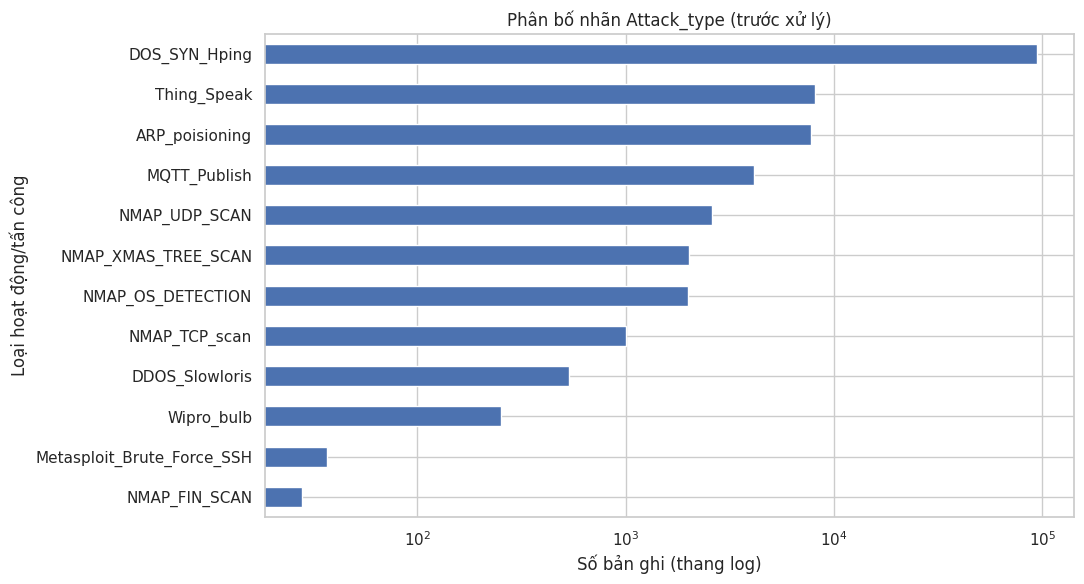

In [4]:
label_counts = df["Attack_type"].value_counts()
label_summary = pd.DataFrame({"Số mẫu": label_counts, "Tỷ lệ (%)": (label_counts / len(df) * 100).round(3)})
display(label_summary)
fig, ax = plt.subplots(figsize=(11, 6))
label_counts.sort_values().plot.barh(ax=ax)
ax.set_title("Phân bố nhãn Attack_type (trước xử lý)")
ax.set_xlabel("Số bản ghi (thang log)")
ax.set_ylabel("Loại hoạt động/tấn công")
ax.set_xscale('log')
fig.tight_layout()
fig.savefig(FIG_DIR / '01_phan_bo_nhan.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Khám phá biến phân loại và phân phối biến số

`proto`, `service` là biến định tính, cần mã hóa trước khi đưa vào Random Forest/MLP. Một số biến số có phân phối lệch nhiều; với **MLP** sẽ dùng `log1p` rồi `StandardScaler` (tính thông số trên train).


Tần suất proto:


,Số mẫu
proto,
tcp,110427
udp,12633
icmp,57



Tần suất service:


,Số mẫu
service,
-,102861
dns,9753
mqtt,4132
http,3464
ssl,2663
ntp,121
dhcp,50
irc,43
ssh,28


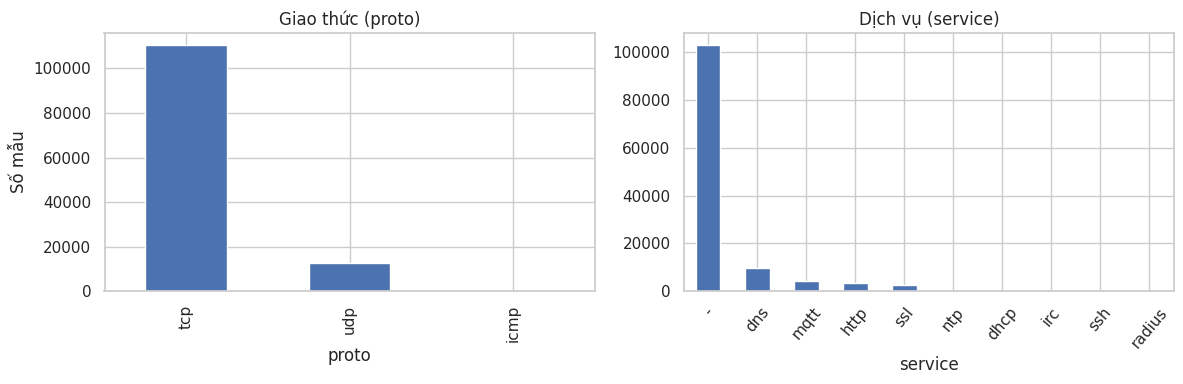

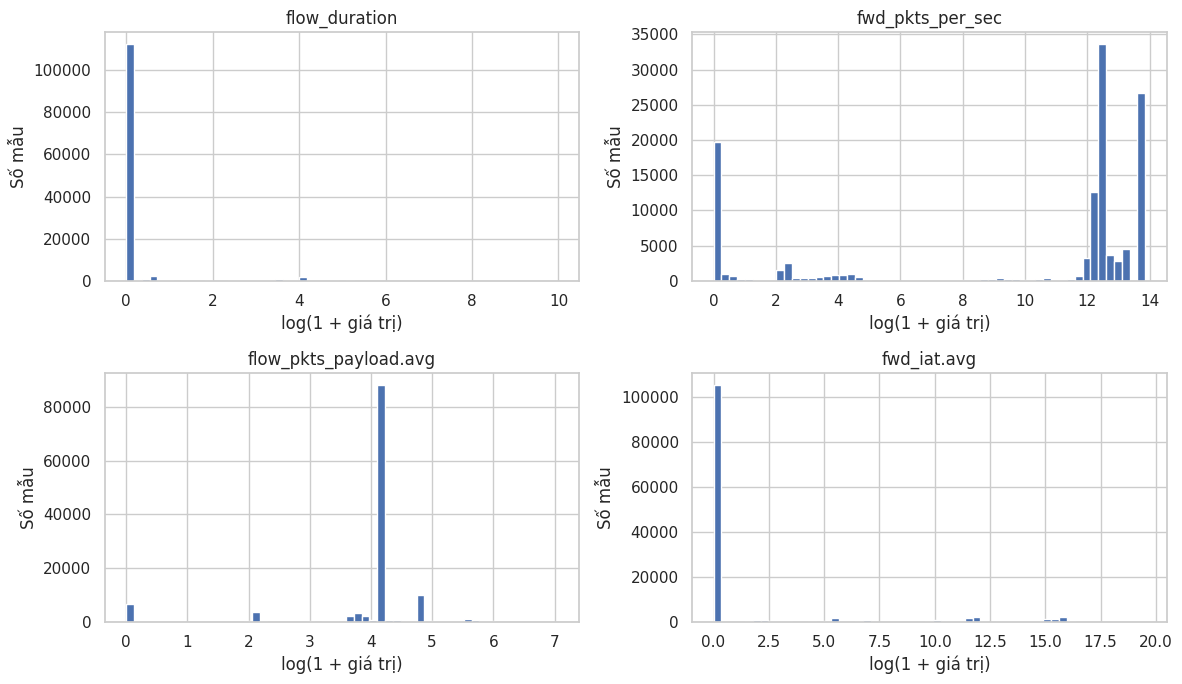

In [5]:
for col in ["proto", "service"]:
    print(f"\nTần suất {col}:")
    display(df[col].value_counts(dropna=False).to_frame("Số mẫu"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["proto"].value_counts().plot.bar(ax=axes[0])
axes[0].set_title("Giao thức (proto)")
axes[0].set_ylabel("Số mẫu")
df["service"].value_counts().plot.bar(ax=axes[1])
axes[1].set_title("Dịch vụ (service)")
axes[1].tick_params(axis='x', rotation=50)
fig.tight_layout()
fig.savefig(FIG_DIR / '02_proto_service.png', dpi=150, bbox_inches='tight')
plt.show()
cols_to_show = ["flow_duration", "fwd_pkts_per_sec", "flow_pkts_payload.avg", "fwd_iat.avg"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flat, cols_to_show):
    ax.hist(np.log1p(df[col].clip(lower=0)), bins=55)
    ax.set_title(col)
    ax.set_xlabel("log(1 + giá trị)")
    ax.set_ylabel("Số mẫu")
fig.tight_layout()
fig.savefig(FIG_DIR / '03_phan_phoi_dac_trung.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Khảo sát ngoại lệ và tương quan

Giá trị cực đại lớn **không đồng nghĩa dữ liệu sai** trong mạng IoT (tấn công có thể làm tăng mạnh tốc độ gói tin). Vì vậy **không xóa hàng chỉ do vượt IQR**; ghi nhận phân phối, dùng biến đổi log khi thích hợp. Tính tương quan minh họa, không quyết định loại cột chỉ vì tương quan cao.

,min,Q1,median,Q3,p99,max
flow_duration,0.0,0.000,0.000,0.0,62.044,2.172834e+04
fwd_pkts_per_sec,0.0,74.544,246723.765,524288.0,1048576.000,1.048576e+06
flow_pkts_payload.avg,0.0,60.000,60.000,60.0,279.720,1.156085e+03
fwd_iat.avg,0.0,0.000,0.000,0.0,6888437.329,3.002526e+08


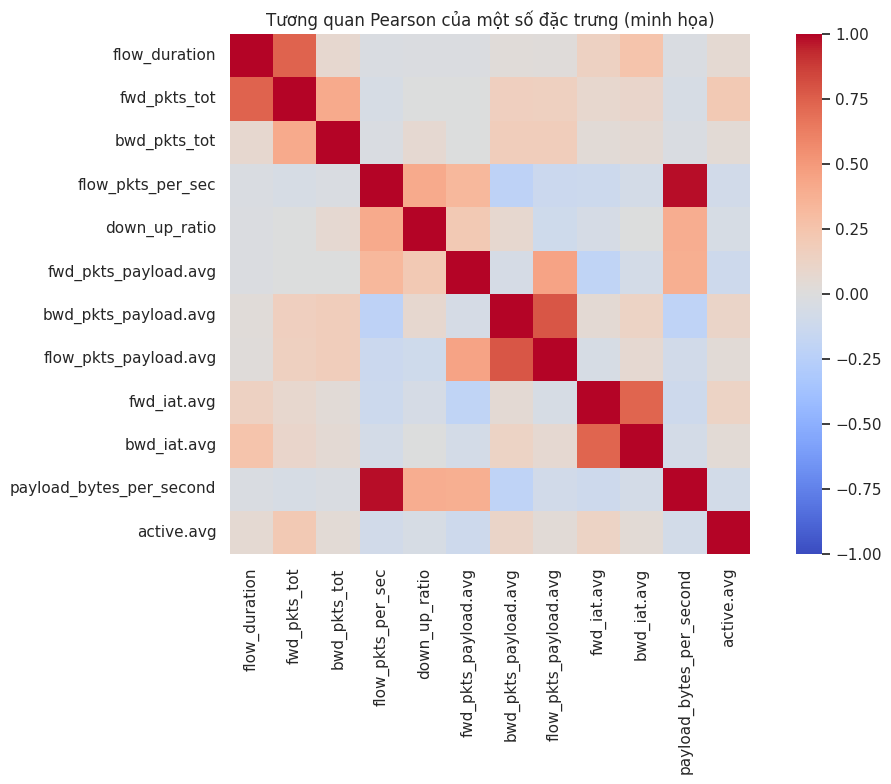

In [6]:
numeric_cols_original = df.select_dtypes(include="number").columns.drop(index_cols, errors='ignore')
quantile_table = df[numeric_cols_original].quantile([0, .25, .50, .75, .99, 1]).T
quantile_table.columns = ['min','Q1','median','Q3','p99','max']
display(quantile_table.loc[[c for c in cols_to_show if c in quantile_table.index]].round(3))
chosen_corr = ["flow_duration", "fwd_pkts_tot", "bwd_pkts_tot", "flow_pkts_per_sec", "down_up_ratio", "fwd_pkts_payload.avg", "bwd_pkts_payload.avg", "flow_pkts_payload.avg", "fwd_iat.avg", "bwd_iat.avg", "payload_bytes_per_second", "active.avg"]
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(df[chosen_corr].corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title("Tương quan Pearson của một số đặc trưng (minh họa)")
fig.tight_layout()
fig.savefig(FIG_DIR / '04_tuong_quan.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Làm sạch chung (trước khi chia)

1. Bỏ `Unnamed: 0` vì là chỉ mục từ file CSV, không phải tín hiệu mạng.
2. Bỏ bản sao trùng **tất cả cột còn lại** (bao gồm nhãn), để tránh lặp lại dữ liệu.
3. Bỏ các hàng có cùng toàn bộ **đặc trưng** nhưng nhãn khác nhau: không đủ bằng chứng xác định nhãn đúng, và tránh tình trạng cùng `X` mang hai nhãn trái ngược. Ghi lại số hàng bị loại (rất ít).
4. Bỏ cột hằng `bwd_URG_flag_count` vì không đóng góp thông tin phân biệt.
5. Không xóa các ngoại lệ chỉ theo ngưỡng thống kê; chúng có thể là dấu hiệu tấn công thật.

**Lưu ý:** Việc khử trùng và xung đột ở đây chỉ dựa vào các giá trị gốc (không học thống kê từ test). Nếu bộ dữ liệu sau này có thông tin phiên/thiết bị/thời gian thì cần cân nhắc chia theo nhóm hoặc theo thời gian để đánh giá sát triển khai thực tế.

In [7]:
clean = df.drop(columns=index_cols).drop_duplicates().copy()
feature_cols = [c for c in clean.columns if c != 'Attack_type']
conflict_mask_clean = clean.duplicated(subset=feature_cols, keep=False)
removed_conflicts = int(conflict_mask_clean.sum())
clean = clean.loc[~conflict_mask_clean].copy()
drop_constants = [c for c in constant_cols if c in clean.columns and c != 'Attack_type']
clean = clean.drop(columns=drop_constants).reset_index(drop=True)
assert clean['Attack_type'].nunique() == df['Attack_type'].nunique(), 'Một lớp đã biến mất!'
assert not clean.duplicated().any()
assert not clean.drop(columns='Attack_type').duplicated().any()
print(f"Kích thước trước: {df.shape} | Sau: {clean.shape}")
print(f"Bỏ {exact_dups:,} dòng trùng, {removed_conflicts} dòng nhãn mâu thuẫn; cột hằng: {drop_constants}")
print('Lớp sau xử lý:')
display(clean['Attack_type'].value_counts().to_frame('Số mẫu'))

Kích thước trước: (123117, 85) | Sau: (117909, 83)
Bỏ 5,195 dòng trùng, 13 dòng nhãn mâu thuẫn; cột hằng: ['bwd_URG_flag_count']
Lớp sau xử lý:


,Số mẫu
Attack_type,
DOS_SYN_Hping,90089
Thing_Speak,7650
ARP_poisioning,7620
MQTT_Publish,4142
NMAP_UDP_SCAN,2582
NMAP_XMAS_TREE_SCAN,2010
NMAP_OS_DETECTION,2000
NMAP_TCP_scan,1002
DDOS_Slowloris,532


## 7. Chia train/test phân tầng, cố định random_state

Tỷ lệ **80% train / 20% test**, `stratify=y` giữ gần đúng tỷ lệ các nhãn. Trong giai đoạn tuning, chỉ dùng cross-validation trên train. Test dùng một lần để báo cáo kết quả cuối cùng.

In [8]:
X = clean.drop(columns='Attack_type')
y = clean['Attack_type']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)
class_compare = pd.concat([
    y.value_counts(normalize=True).rename('Toàn bộ'),
    y_train.value_counts(normalize=True).rename('Train'),
    y_test.value_counts(normalize=True).rename('Test')], axis=1).mul(100).round(3)
display(class_compare)
assert set(y_train) == set(y_test) == set(y)
assert set(X_train.index).isdisjoint(set(X_test.index))
print('Kiểm tra: không có dòng thuộc cả train và test (theo chỉ số).')

Train: (94327, 82) | Test: (23582, 82)


,Toàn bộ,Train,Test
Attack_type,,,
DOS_SYN_Hping,76.406,76.405,76.406
Thing_Speak,6.488,6.488,6.488
ARP_poisioning,6.463,6.463,6.463
MQTT_Publish,3.513,3.512,3.515
NMAP_UDP_SCAN,2.190,2.190,2.188
NMAP_XMAS_TREE_SCAN,1.705,1.705,1.705
NMAP_OS_DETECTION,1.696,1.696,1.696
NMAP_TCP_scan,0.850,0.850,0.848
DDOS_Slowloris,0.451,0.452,0.449


Kiểm tra: không có dòng thuộc cả train và test (theo chỉ số).


## 8. Bộ tiền xử lý RIÊNG cho Random Forest và MLP

- **Cả hai mô hình:** One-Hot Encoding với `handle_unknown='ignore'`, nên dịch vụ chưa xuất hiện trong train sẽ không gây lỗi khi dự đoán.
- **Random Forest:** giữ nguyên các biến số; mô hình cây không yêu cầu scale.
- **MLP:** tất cả biến số quan sát được không âm nên áp dụng `log1p`, sau đó `StandardScaler`; chỉ số trung bình/độ lệch chuẩn được học từ train.
- **Mất cân bằng:** không SMOTE/undersampling toàn dữ liệu trước split. Có thể thử `class_weight='balanced'` cho Random Forest, sample weights/chiến lược khác cho MLP **chỉ trên train và trong CV**. Cần so sánh Macro F1 và Recall của lớp hiếm.

Những transformer này được lưu để bạn dùng lại trong phần huấn luyện và đảm bảo thao tác nhất quán.

In [9]:
cat_cols = X_train.select_dtypes(include=['object','category']).columns.tolist()
num_cols = X_train.select_dtypes(include='number').columns.tolist()
assert len(cat_cols) == 2, f'Cột phân loại không như dự kiến: {cat_cols}'
assert (X_train[num_cols].to_numpy() >= 0).all(), 'Có số âm: cần xem lại log1p cho các cột này'

def make_preprocessors():
    rf_prep = ColumnTransformer([
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ], remainder='drop', sparse_threshold=0)
    mlp_prep = ColumnTransformer([
        ('num', Pipeline([
            ('log1p', FunctionTransformer(np.log1p, validate=False)),
            ('scale', StandardScaler()),
        ]), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    ], remainder='drop', sparse_threshold=0)
    return rf_prep, mlp_prep

rf_preprocessor, mlp_preprocessor = make_preprocessors()
# CHỈ fit trên train; không fit hoặc fit_transform trên test.
rf_preprocessor.fit(X_train)
mlp_preprocessor.fit(X_train)
rf_check = rf_preprocessor.transform(X_test.iloc[:100])
mlp_check = mlp_preprocessor.transform(X_test.iloc[:100])
print('Cột số:',len(num_cols),'| Cột chữ:',cat_cols)
print('Shape sau RF preprocessing:',rf_check.shape)
print('Shape sau MLP preprocessing:',mlp_check.shape)
assert np.isfinite(rf_check).all() and np.isfinite(mlp_check).all()
print('Kết quả kiểm tra: không có NaN/Inf sau xử lý.')

Cột số: 80 | Cột chữ: ['proto', 'service']
Shape sau RF preprocessing: (100, 92)
Shape sau MLP preprocessing: (100, 92)
Kết quả kiểm tra: không có NaN/Inf sau xử lý.


## 9. Xuất dữ liệu dùng chung cho thành viên xây dựng mô hình

Dữ liệu train/test lưu **sau làm sạch cơ bản, chưa mã hóa/chuẩn hóa sẵn**, giúp thuận tiện huấn luyện bằng `Pipeline` trong cross-validation mà không rò rỉ giữa các fold. `rf_preprocessor.joblib`, `mlp_preprocessor.joblib` đã fit train để sử dụng khi cần chạy đánh giá trên test hoặc demo; **nếu tuning bằng CV, hãy tạo preprocessor mới bằng `make_preprocessors()` và đưa vào pipeline để mỗi fold tự fit lại**.

Chạy lại notebook sẽ tái tạo các tệp dựa trên `RT_IOT2022.csv` và seed 42.

In [10]:
train_out = X_train.assign(Attack_type=y_train)
test_out = X_test.assign(Attack_type=y_test)
train_path = OUTPUT_DIR / 'train.csv.gz'
test_path = OUTPUT_DIR / 'test.csv.gz'
train_out.to_csv(train_path, index=False, compression='gzip')
test_out.to_csv(test_path, index=False, compression='gzip')
joblib.dump(rf_preprocessor, OUTPUT_DIR / 'rf_preprocessor.joblib', compress=3)
joblib.dump(mlp_preprocessor, OUTPUT_DIR / 'mlp_preprocessor.joblib', compress=3)
metadata = {
    'original_shape': list(df.shape),
    'clean_shape': list(clean.shape),
    'n_classes': int(y.nunique()),
    'index_columns_removed': index_cols,
    'constant_columns_removed': drop_constants,
    'exact_duplicate_rows_removed': exact_dups,
    'ambiguous_label_rows_removed': removed_conflicts,
    'ambiguous_feature_groups': conflict_groups,
    'random_state': RANDOM_STATE,
    'test_size': .2,
    'train_size': len(train_out),
    'test_n': len(test_out),
    'target': 'Attack_type',
    'categorical_features': cat_cols,
    'numerical_features': num_cols,
    'class_counts_clean': y.value_counts().to_dict(),
    'class_counts_train': y_train.value_counts().to_dict(),
    'class_counts_test': y_test.value_counts().to_dict(),
    'note': 'Keep preprocessing inside a fresh Pipeline during cross-validation to avoid leakage.'
}
(OUTPUT_DIR / 'metadata.json').write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8')
label_summary.to_csv(OUTPUT_DIR / 'nhan_goc.csv', encoding='utf-8-sig')
print('Đã lưu:')
for fp in sorted(OUTPUT_DIR.iterdir()):
    if fp.is_file():
        print(f' - {fp} ({fp.stat().st_size / 1024 / 1024:.2f} MB)')

Đã lưu:
 - rt_iot_eda_outputs/metadata.json (0.00 MB)
 - rt_iot_eda_outputs/mlp_preprocessor.joblib (0.00 MB)
 - rt_iot_eda_outputs/nhan_goc.csv (0.00 MB)
 - rt_iot_eda_outputs/rf_preprocessor.joblib (0.00 MB)
 - rt_iot_eda_outputs/test.csv.gz (0.84 MB)
 - rt_iot_eda_outputs/train.csv.gz (3.31 MB)


## 10. Kiểm tra file xuất và ví dụ đọc trong notebook xây dựng mô hình

**Cách dùng cho phần mô hình**: `train.csv.gz` / `test.csv.gz` là 2 tập đã chia. Khi huấn luyện nên dùng sklearn `Pipeline([('preprocess', make_preprocessors()[0]), ('model', RandomForestClassifier(...))])` (tương tự MLP), `GridSearchCV` chỉ trên train, rồi mới `predict(X_test)`.

**Không nên:** `fit_transform` bộ tiền xử lý trên cả train + test, tuning dựa vào test, hay cân bằng lớp trước split.

**Hạn chế:** Đây là split ngẫu nhiên, chưa có metadata phiên/thiết bị để đánh giá ngoài phân phối hoặc kiểm tra tính tổng quát trên thiết bị mới.

In [11]:
reload_train = pd.read_csv(train_path)
reload_test = pd.read_csv(test_path)
assert reload_train.shape == train_out.shape
assert reload_test.shape == test_out.shape
assert not reload_train.isna().any().any() and not reload_test.isna().any().any()
assert set(reload_train['Attack_type']) == set(reload_test['Attack_type'])
print('✓ Đọc lại file nén thành công')
print('✓ Train:', reload_train.shape, '| Test:', reload_test.shape)
print('✓ Không có missing và đủ 12 nhãn ở cả 2 tập')
print('Hoàn thành EDA & tiền xử lý dữ liệu.')

✓ Đọc lại file nén thành công
✓ Train: (94327, 83) | Test: (23582, 83)
✓ Không có missing và đủ 12 nhãn ở cả 2 tập
Hoàn thành EDA & tiền xử lý dữ liệu.
